# ARIES Benchmark — Graph Analysis
### Notebook 02 · Graph Transformation (Nodes, Edges, Density, Topology, Constraints)

**In an argumentative graph:**
Each `argument` in the CSV is a document whose ADUs (sentences/clauses) are **nodes**.
The annotated relations between them (Inference / Conflict) are **directed edges**.
Neutral pairs are NOT edges — they are the absence of a relation.

```
argument (document)
│
├── ADU_1 (node)  ──Inference──►  ADU_3 (node)   ← edge
├── ADU_2 (node)  ──Inference──►  ADU_3 (node)   ← edge
└── ADU_2 (node)  ──Conflict───►  ADU_4 (node)   ← edge
```


---
## 0 · Setup


In [20]:
import subprocess, sys
PKGS = ['pandas','numpy','matplotlib','seaborn','scipy','tabulate','networkx','tqdm']
subprocess.run([sys.executable,'-m','pip','install','--quiet']+PKGS)
print('Dependencies installed')


Dependencies installed


In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import networkx as nx
from scipy import stats
from tabulate import tabulate
from tqdm import tqdm
from collections import Counter, defaultdict
import ast, re, json, warnings
from pathlib import Path
warnings.filterwarnings('ignore')

sns.set_style('whitegrid')
plt.rcParams.update({
    'figure.facecolor':'#ffffff','axes.facecolor':'#ffffff',
    'axes.edgecolor':'#000000','axes.labelcolor':'#000000',
    'xtick.color':'#000000','ytick.color':'#000000',
    'text.color':'#000000','grid.color':'#cccccc',
    'grid.linewidth':0.5,'figure.dpi':110,
})
PALETTE = ['#5b8dee','#f06060','#3ecf8e','#f0a500','#7c5ce6','#a29bfe','#fd79a8','#00b894']
REL_COLOR = {1:'#5b8dee', 2:'#f06060'}   # Inference=blue, Conflict=red

print('Imports OK')


Imports OK


---
## 1 · Load CSV and filter auto-arcs

The data is loaded by filtering out Neural relation type, as they represent the absence of a relation

In [61]:
# Canonical column names (established in Notebook 01)
COL = {
    'argument':  'argument',
    'p1':        'proposition_1',
    'p2':        'proposition_2',
    'relation':  'relations',
    'dataset':   'data_source',
    'all_rel':   'all_relations',
    'indexes':   'start_end_indexes',
}

# Corpus name normalisation (internal aliases → paper names)
CORPUS_NAMES = {
    'Cuties':    'QT30',
    'US2016R1':  'US2016_Reddit',
    'Microtext':  'MTC',
    'ABstRACT':   'AbstRCT',
}

In [ ]:
# ── CONFIGURE: path to your CSV ──────────────────────────────────────────
CSV_PATH = '../data/aries/data.csv'

# Auto-detect separator
import csv as _csv

df_raw = pd.read_csv(CSV_PATH, sep=',', dtype=str, keep_default_na=False)
df_raw['relations'] = pd.to_numeric(df_raw['relations'], errors='coerce')


df_raw['corpus'] = df_raw[COL['dataset']].replace(CORPUS_NAMES)

# ── Normalize P1 and P2 ONCE at load time ────────────────────────────────
# All P2 values have a leading and trailing space in the CSV (preprocessing
# artifact). Stripping here ensures consistent node IDs across all graphs.
df_raw[COL['p1']] = df_raw[COL['p1']].str.strip()
df_raw[COL['p2']] = df_raw[COL['p2']].str.strip()

# Filter auto-arcs (P1 == P2) — always Neutral, no argumentative content
df = df_raw[df_raw[COL['p1']] != df_raw[COL['p2']]].copy()

n_removed = len(df_raw) - len(df)
print(f'Raw rows      : {len(df_raw):>7,}')
print(f'Auto-arcs     : {n_removed:>7,}  ({100*n_removed/len(df_raw):.2f}%)')
print(f'Clean rows    : {len(df):>7,}')
print()
print('Relation distribution after filter:')
for k,v in df[COL['relation']].value_counts().sort_index().items():
    lbl = {0:'Neutral  ',1:'Inference',2:'Conflict '}[int(k)]
    print(f'  {lbl} ({int(k)}): {v:>6,}  ({100*v/len(df):.1f}%)')

df.head(5)




In [55]:
# Instances (ADU) frequency per data_source
data_source_counts = df['data_source'].value_counts().reset_index()
data_source_counts.columns = ['data_source', 'ADU_pairs']

# Unique arguments per data_source
unique_args_per_source = df.groupby('data_source')['argument'].nunique().reset_index()
unique_args_per_source.columns = ['data_source', 'unique_arguments']

combined = data_source_counts.merge(unique_args_per_source, on='data_source')

# New column: ADU_pairs / unique_arguments
combined['pairs_per_argument'] = (combined['ADU_pairs'] / combined['unique_arguments']).round(0)

totals = {
    'data_source': 'TOTAL',
    'ADU_pairs': combined['ADU_pairs'].sum(),
    'unique_arguments': combined['unique_arguments'].sum(),
    'pairs_per_argument': (combined['ADU_pairs'].sum() / combined['unique_arguments'].sum()).round(0)
}

combined_with_totals = pd.concat([combined, pd.DataFrame([totals])], ignore_index=True)

print("\nData source distribution:")
print(tabulate(combined_with_totals, headers='keys', tablefmt='rounded_outline', showindex=False))




Data source distribution:
╭───────────────┬─────────────┬────────────────────┬──────────────────────╮
│ data_source   │   ADU_pairs │   unique_arguments │   pairs_per_argument │
├───────────────┼─────────────┼────────────────────┼──────────────────────┤
│ ACSP          │       26245 │                 40 │                  656 │
│ AAEC          │       15217 │                402 │                   38 │
│ US2016        │       10694 │                438 │                   24 │
│ Cuties        │        9591 │                680 │                   14 │
│ ABstRACT      │        6006 │                658 │                    9 │
│ US2016R1      │        3301 │                146 │                   23 │
│ CDCP          │        2286 │                 70 │                   33 │
│ Microtext     │         888 │                112 │                    8 │
│ TOTAL         │       74228 │               2546 │                   29 │
╰───────────────┴─────────────┴────────────────────┴─────────

---
## 2 · Graph construction

Each **document** (`argument`) becomes a directed graph `G = (V, E)` where:
- **V** = set of unique ADUs that appear in at least one non-Neutral pair
- **E** = set of directed edges `(P1 → P2)` with `relation ∈ {Inference, Conflict}`

Neutral pairs are **not** edges. They represent the absence of a relation.

```
df row  →  relation=1  →  edge  P1 ──Inference──► P2
df row  →  relation=2  →  edge  P1 ──Conflict───► P2
df row  →  relation=0  →  (no edge)
```


In [53]:
def build_graph(subset):
    G = nx.DiGraph()
    # All ADUs as nodes — P1 and P2 already stripped at load time
    all_adus = pd.concat([subset[COL['p1']], subset[COL['p2']]]).unique()
    for adu in all_adus:
        G.add_node(adu)
    # Edges only for non-Neutral, non-self-loop pairs
    real = subset[subset[COL['relation']] != 0]
    for _, row in real.iterrows():
        p1, p2 = row[COL['p1']], row[COL['p2']]
        if p1 != p2:
            G.add_edge(p1, p2, rel=int(row[COL['relation']]))
    return G

# ── Build one graph per argument ─────────────────────────────────────────
graphs = {}   # key = (corpus, argument_text) → value = nx.DiGraph

for (corpus, arg), grp in tqdm(df.groupby(['corpus', COL['argument']]),
                                desc='Building graphs'):
    G = build_graph(grp)
    if G.number_of_nodes() > 0:
        graphs[(corpus, arg)] = G

print(f'Graphs built: {len(graphs):,}')
print(f'  (arguments with at least one non-Neutral edge)')


Building graphs: 100%|██████████| 2546/2546 [00:04<00:00, 578.15it/s] 

Graphs built: 2,546
  (arguments with at least one non-Neutral edge)


In [6]:
# ── Inspect one example: the Microtext argument from Notebook 01 ─────────
example_key = [(c, a) for c, a in graphs if c == 'MTC' and 'Considering' in a]
if not example_key:
    example_key = [(c, a) for c, a in graphs if c == 'MTC']

if example_key:
    ek = example_key[0]
    G_ex = graphs[ek]
    print(f'Example graph — corpus: {ek[0]}')
    print(f'  Nodes : {G_ex.number_of_nodes()}')
    print(f'  Edges : {G_ex.number_of_edges()}')
    print()
    print('  Edges (P1 → P2 : type):')
    REL_LBL = {1:'Inference', 2:'Conflict'}
    for u, v, d in G_ex.edges(data=True):
        print(f'    "{u[:45]}..." ──{REL_LBL[d["rel"]]}──► "{v[:45]}..."')


Example graph — corpus: MTC
  Nodes : 6
  Edges : 4

  Edges (P1 → P2 : type):
    "Considering what's on television these days, ..." ──Conflict──► "Nevertheless one has to point out that there'..."
    "Considering what's on television these days, ..." ──Inference──► "so there's no advantage for the current payin..."
    "Considering what's on television these days, ..." ──Inference──► "In some cases there are only shows for older ..."
    "so there's no advantage for the current payin..." ──Inference──► "By now you have advertising on all channels,..."


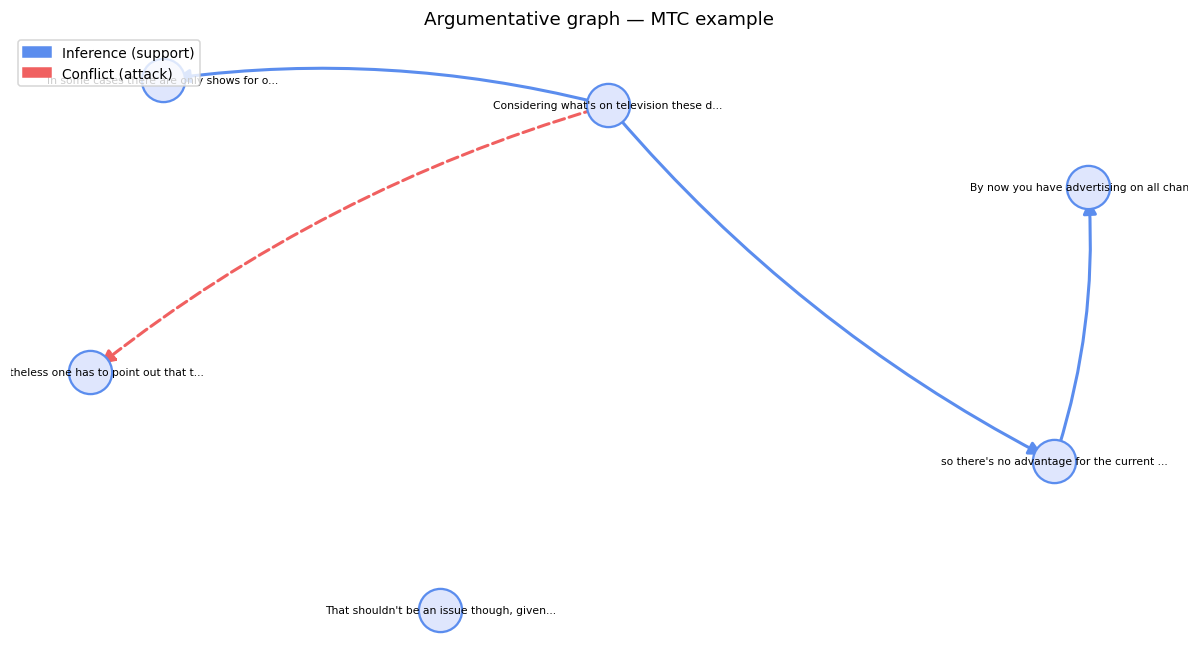

In [7]:
# ── Visualise the example graph ──────────────────────────────────────────
if example_key:
    G_ex = graphs[ek]
    fig, ax = plt.subplots(figsize=(11, 6))

    # Shorten node labels for display
    labels = {n: n[:40]+'...' if len(n)>40 else n for n in G_ex.nodes()}
    pos = nx.spring_layout(G_ex, seed=42, k=2.5)

    # Color edges by relation type
    inf_edges = [(u,v) for u,v,d in G_ex.edges(data=True) if d['rel']==1]
    con_edges = [(u,v) for u,v,d in G_ex.edges(data=True) if d['rel']==2]

    nx.draw_networkx_nodes(G_ex, pos, ax=ax, node_size=800,
                           node_color='#dfe6fd', edgecolors='#5b8dee', linewidths=1.5)
    nx.draw_networkx_labels(G_ex, pos, labels, ax=ax, font_size=7)
    nx.draw_networkx_edges(G_ex, pos, edgelist=inf_edges, ax=ax,
                           edge_color='#5b8dee', arrows=True,
                           arrowsize=18, width=2,
                           connectionstyle='arc3,rad=0.1')
    nx.draw_networkx_edges(G_ex, pos, edgelist=con_edges, ax=ax,
                           edge_color='#f06060', arrows=True,
                           arrowsize=18, width=2, style='dashed',
                           connectionstyle='arc3,rad=0.1')

    legend = [mpatches.Patch(color='#5b8dee', label='Inference (support)'),
              mpatches.Patch(color='#f06060', label='Conflict (attack)')]
    ax.legend(handles=legend, loc='upper left', fontsize=9)
    ax.set_title(f'Argumentative graph — {ek[0]} example', fontsize=12)
    ax.axis('off')
    plt.tight_layout()
    plt.savefig('fig_graph_example.png', dpi=150, bbox_inches='tight')
    plt.show()


---
## 3 · Node-level metrics

For each node (ADU) in a graph we compute:

| Metric | Formula | Interpretation |
|---|---|---|
| **in-degree** | edges arriving at node | how many ADUs support/attack this one |
| **out-degree** | edges leaving node | how many ADUs this one supports/attacks |
| **total degree** | in + out | overall connectivity |
| **root** | in-degree = 0 AND out-degree > 0 | candidate MajorClaim / central claim |
| **leaf** | out-degree = 0 AND in-degree > 0 | terminal premise, no further support |
| **isolated** | degree = 0 | ADU with no argumentative connection |


In [9]:
def node_metrics(G):
    """Return per-node metrics dict for a single graph."""
    metrics = []
    for node in G.nodes():
        ind  = G.in_degree(node)
        outd = G.out_degree(node)
        metrics.append({
            'node':       node,
            'in_degree':  ind,
            'out_degree': outd,
            'degree':     ind + outd,
            'is_root':    ind == 0 and outd > 0,   # emits but receives nothing
            'is_leaf':    outd == 0 and ind > 0,   # receives but emits nothing
            'is_isolated': ind == 0 and outd == 0, # no connections at all
        })
    return metrics

# ── Collect node metrics across all graphs ────────────────────────────────
all_node_rows = []
for (corpus, arg), G in graphs.items():
    for m in node_metrics(G):
        m['corpus'] = corpus
        all_node_rows.append(m)

node_df = pd.DataFrame(all_node_rows)
print(f'Total nodes across all graphs: {len(node_df):,}')
print()

# Global degree distribution
print('Degree distribution (global):')
print(node_df[['in_degree','out_degree','degree']].describe().round(2))
print()

# Root / leaf / isolated counts
print('Node roles (global):')
print(f'  Roots    (in=0, out>0): {node_df["is_root"].sum():>6,}  ({100*node_df["is_root"].mean():.1f}%)')
print(f'  Leaves   (out=0, in>0): {node_df["is_leaf"].sum():>6,}  ({100*node_df["is_leaf"].mean():.1f}%)')
print(f'  Isolated (deg=0):       {node_df["is_isolated"].sum():>6,}  ({100*node_df["is_isolated"].mean():.1f}%)')
print(f'  Internal (in>0,out>0):  {((node_df["in_degree"]>0)&(node_df["out_degree"]>0)).sum():>6,}')


Total nodes across all graphs: 37,174

Degree distribution (global):
       in_degree  out_degree    degree
count   37174.00    37174.00  37174.00
mean        0.63        0.63      1.26
std         0.61        1.02      1.04
min         0.00        0.00      0.00
25%         0.00        0.00      1.00
50%         1.00        0.00      1.00
75%         1.00        1.00      1.00
max        13.00       14.00     14.00

Node roles (global):
  Roots    (in=0, out>0): 10,211  (27.5%)
  Leaves   (out=0, in>0): 16,824  (45.3%)
  Isolated (deg=0):        5,380  (14.5%)
  Internal (in>0,out>0):   4,759


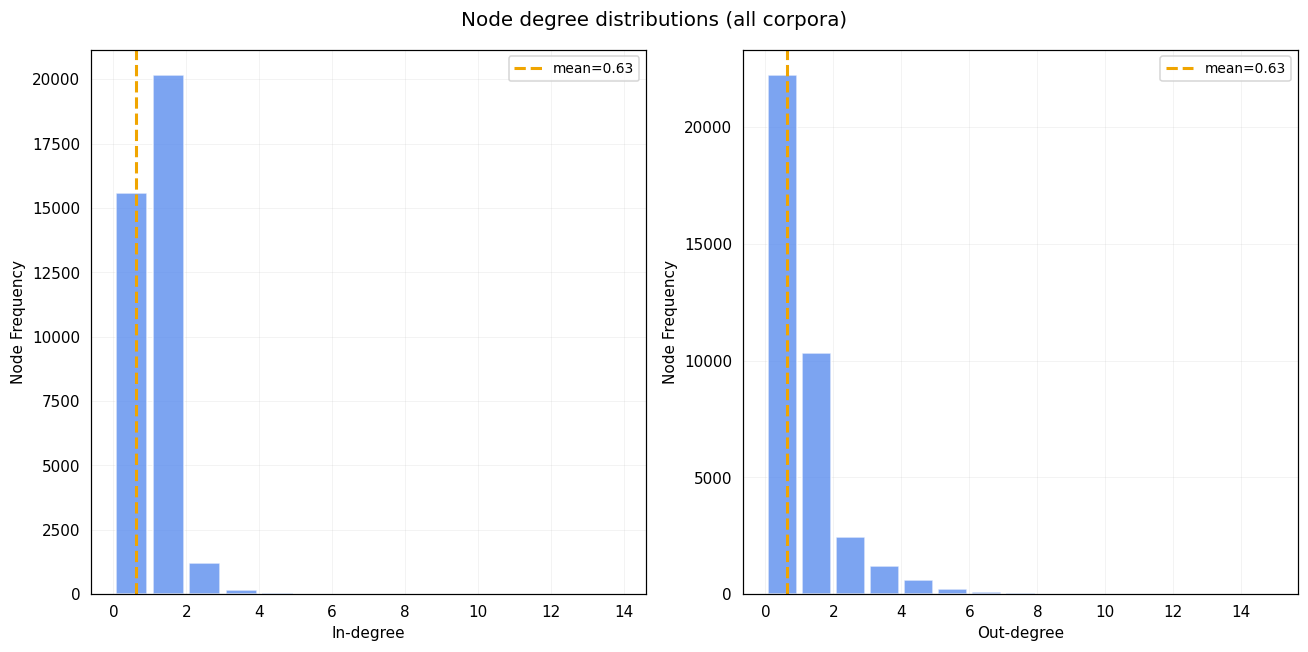

In [10]:
# ── Degree distribution plot ──────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
fig.suptitle('Node degree distributions (all corpora)', fontsize=13)

for ax, col, title in zip(axes,
                           ['in_degree','out_degree'],
                           ['In-degree','Out-degree']):
    vals = node_df[col]
    max_v = min(vals.max(), 20)
    ax.hist(vals[vals <= max_v], bins=range(0, int(max_v)+2),
            color=PALETTE[0], alpha=0.8, edgecolor='white', rwidth=0.85)
    ax.axvline(vals.mean(), color=PALETTE[3], lw=2, ls='--',
               label=f'mean={vals.mean():.2f}')
    ax.set_xlabel(title); ax.set_ylabel('Node Frequency')
    ax.legend(fontsize=9); ax.grid(True, alpha=0.3)

plt.tight_layout()
# plt.savefig('fig_degree_distribution.png', dpi=150, bbox_inches='tight')
plt.show()


Mean degree per corpus:
╭───────────────┬─────────────┬──────────────┬──────────╮
│ corpus        │   in_degree │   out_degree │   degree │
├───────────────┼─────────────┼──────────────┼──────────┤
│ AAEC          │       0.886 │        0.886 │    1.771 │
│ ACSP          │       0.693 │        0.693 │    1.385 │
│ AbstRCT       │       0.758 │        0.758 │    1.516 │
│ CDCP          │       0.535 │        0.535 │    1.071 │
│ MTC           │       0.66  │        0.66  │    1.319 │
│ QT30          │       0.423 │        0.423 │    0.847 │
│ US2016        │       0.532 │        0.532 │    1.063 │
│ US2016_Reddit │       0.515 │        0.515 │    1.029 │
╰───────────────┴─────────────┴──────────────┴──────────╯


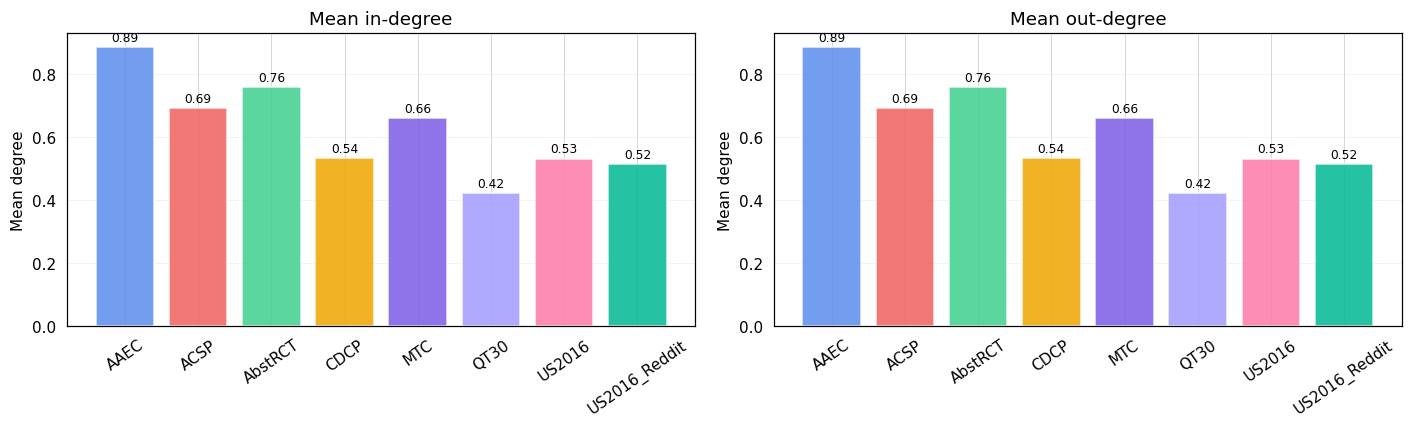

In [11]:
# ── In/Out-degree by corpus ───────────────────────────────────────────────
deg_by_corpus = (node_df.groupby('corpus')[['in_degree','out_degree','degree']]
                         .mean().round(3).reset_index())
print('Mean degree per corpus:')
print(tabulate(deg_by_corpus, headers='keys', tablefmt='rounded_outline', showindex=False))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, metric, title in zip(axes, ['in_degree','out_degree'],
                                    ['Mean in-degree','Mean out-degree']):
    corpora = deg_by_corpus['corpus']
    vals    = deg_by_corpus[metric]
    bars = ax.bar(corpora, vals, color=PALETTE[:len(corpora)], alpha=0.85)
    for bar, v in zip(bars, vals):
        ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.01,
                f'{v:.2f}', ha='center', va='bottom', fontsize=8)
    ax.set_title(title); ax.set_ylabel('Mean degree')
    ax.tick_params(axis='x', rotation=35); ax.grid(True, axis='y', alpha=0.3)
plt.tight_layout()
# plt.savefig('fig_degree_by_corpus.png', dpi=150, bbox_inches='tight')
plt.show()


---
## 4 · Graph-level metrics

For each document graph we compute:

| Metric | Formula | Interpretation |
|---|---|---|
| **N nodes** | `|V|` | number of ADUs with at least one relation |
| **E edges** | `|E|` | number of annotated argumentative relations |
| **density** | `E / (N×(N-1))` | how connected relative to maximum possible |
| **n_inference** | count edges with rel=1 | support relations |
| **n_conflict** | count edges with rel=2 | attack relations |
| **n_components** | weakly connected components | isolated sub-arguments |
| **max_depth** | longest path from any root | depth of the support chain |
| **branching_factor** | mean out-degree of non-leaf nodes | how many supports per claim |
| **has_cycle** | cycle detection | whether graph is a Directed Acyclic Graph (DAG) or not |


A directed graph has two types of connectivity:

- Strongly connected: A can reach B AND B can reach A by following the direction of the edges.
- Weakly connected: A can reach B if you ignore the direction of the edges—treating all edges as if they were bidirectional.
- A weakly connected component is a subset of nodes where all nodes are connected to one another if you ignore the direction.

In [12]:
def graph_metrics(G, corpus):
    """Compute graph-level metrics for a single argumentative graph."""
    N = G.number_of_nodes()
    E = G.number_of_edges()
    if N == 0:
        return None

    # Edge type counts
    n_inf = sum(1 for _,_,d in G.edges(data=True) if d['rel']==1)
    n_con = sum(1 for _,_,d in G.edges(data=True) if d['rel']==2)

    # Density: actual edges / max possible directed edges
    density = E / (N * (N-1)) if N > 1 else 0

    # Weakly connected components (ignoring edge direction)
    n_comp = nx.number_weakly_connected_components(G)

    # Cycle detection
    has_cycle = not nx.is_directed_acyclic_graph(G)

    # Max depth: longest shortest path from any root node
    roots = [n for n in G.nodes() if G.in_degree(n)==0 and G.out_degree(n)>0]
    if roots and not has_cycle:
        try:
            depths = []
            for r in roots:
                lengths = nx.single_source_shortest_path_length(G, r)
                depths.extend(lengths.values())
            max_depth = max(depths) if depths else 0
        except:
            max_depth = -1
    else:
        max_depth = -1   # undefined for cyclic graphs

    # Branching factor: mean out-degree of nodes that have out-edges
    out_degrees = [d for _, d in G.out_degree() if d > 0]
    branching = np.mean(out_degrees) if out_degrees else 0

    # Node roles
    n_roots    = sum(1 for n in G.nodes() if G.in_degree(n)==0 and G.out_degree(n)>0)
    n_leaves   = sum(1 for n in G.nodes() if G.out_degree(n)==0 and G.in_degree(n)>0)
    n_internal = sum(1 for n in G.nodes() if G.in_degree(n)>0 and G.out_degree(n)>0)

    return {
        'corpus':    corpus,
        'N':         N,
        'E':         E,
        'n_inf':     n_inf,
        'n_con':     n_con,
        'density':   round(density, 4),
        'n_comp':    n_comp,
        'has_cycle': has_cycle,
        'max_depth': max_depth,
        'branching': round(branching, 3),
        'n_roots':   n_roots,
        'n_leaves':  n_leaves,
        'n_internal':n_internal,
    }

# ── Compute for all graphs ────────────────────────────────────────────────
graph_rows = []
for (corpus, arg), G in tqdm(graphs.items(), desc='Computing graph metrics'):
    m = graph_metrics(G, corpus)
    if m:
        graph_rows.append(m)

gdf = pd.DataFrame(graph_rows)
print(f'Graphs analysed: {len(gdf):,}')
print()
print('Global graph statistics:')
print(gdf[['N','E','density','n_comp','max_depth','branching']].describe().round(2))


Computing graph metrics: 100%|██████████| 2546/2546 [00:00<00:00, 8132.10it/s]

Graphs analysed: 2,546

Global graph statistics:
             N        E  density   n_comp  max_depth  branching
count  2546.00  2546.00  2546.00  2546.00    2546.00    2546.00
mean     14.60     9.21     0.13     5.47       1.87       1.80
std      32.26    21.25     0.12    13.29       1.06       0.96
min       2.00     0.00     0.00     1.00      -1.00       0.00
25%       5.00     3.00     0.05     1.00       1.00       1.00
50%       8.00     5.00     0.09     2.00       2.00       1.50
75%      13.00     9.00     0.17     4.00       2.00       2.20
max     423.00   324.00     0.50   223.00      10.00       8.00


In [13]:
# ── Cycles and DAG structure ──────────────────────────────────────────────
n_cyclic = gdf['has_cycle'].sum()
n_dag    = (~gdf['has_cycle']).sum()
print(f'Graphs with cycles (non-DAG): {n_cyclic:,}  ({100*n_cyclic/len(gdf):.1f}%)')
print(f'DAGs (acyclic):               {n_dag:,}  ({100*n_dag/len(gdf):.1f}%)')
print()
print('Cycles by corpus:')
cycle_by_corpus = gdf.groupby('corpus')['has_cycle'].agg(['sum','count'])
cycle_by_corpus['%_cyclic'] = (100*cycle_by_corpus['sum']/cycle_by_corpus['count']).round(1)
cycle_by_corpus.columns = ['n_cyclic','n_total','%_cyclic']
print(tabulate(cycle_by_corpus.reset_index(), headers='keys',
               tablefmt='rounded_outline', showindex=False))


Graphs with cycles (non-DAG): 2  (0.1%)
DAGs (acyclic):               2,544  (99.9%)

Cycles by corpus:
╭───────────────┬────────────┬───────────┬────────────╮
│ corpus        │   n_cyclic │   n_total │   %_cyclic │
├───────────────┼────────────┼───────────┼────────────┤
│ AAEC          │          0 │       402 │        0   │
│ ACSP          │          0 │        40 │        0   │
│ AbstRCT       │          0 │       658 │        0   │
│ CDCP          │          0 │        70 │        0   │
│ MTC           │          0 │       112 │        0   │
│ QT30          │          2 │       680 │        0.3 │
│ US2016        │          0 │       438 │        0   │
│ US2016_Reddit │          0 │       146 │        0   │
╰───────────────┴────────────┴───────────┴────────────╯


In [15]:
# ── Per-corpus summary table ──────────────────────────────────────────────
corpus_summary = gdf.groupby('corpus').agg(
    n_graphs   = ('N','count'),
    N_mean     = ('N','mean'),
    N_max      = ('N','max'),
    E_mean     = ('E','mean'),
    density_mean = ('density','mean'),
    depth_mean = ('max_depth', lambda x: x[x>=0].mean()),
    branch_mean= ('branching','mean'),
    pct_cyclic = ('has_cycle', lambda x: 100*x.mean()),
    n_comp_mean= ('n_comp','mean'),
).round(2).reset_index()

print('Per-corpus graph statistics:')
print(tabulate(corpus_summary, headers='keys', tablefmt='rounded_outline', showindex=False))


Per-corpus graph statistics:
╭───────────────┬────────────┬──────────┬─────────┬──────────┬────────────────┬──────────────┬───────────────┬──────────────┬───────────────╮
│ corpus        │   n_graphs │   N_mean │   N_max │   E_mean │   density_mean │   depth_mean │   branch_mean │   pct_cyclic │   n_comp_mean │
├───────────────┼────────────┼──────────┼─────────┼──────────┼────────────────┼──────────────┼───────────────┼──────────────┼───────────────┤
│ AAEC          │        402 │    15    │      28 │    13.28 │           0.07 │         2.82 │          2.61 │         0    │          1.72 │
│ ACSP          │         40 │   233.92 │     423 │   162.02 │           0    │         2.98 │          1.4  │         0    │         75.45 │
│ AbstRCT       │        658 │     5.28 │      14 │     4    │           0.21 │         1.38 │          2.4  │         0    │          1.32 │
│ CDCP          │         70 │    20.66 │     110 │    11.06 │           0.07 │         2.69 │          1.33 │         

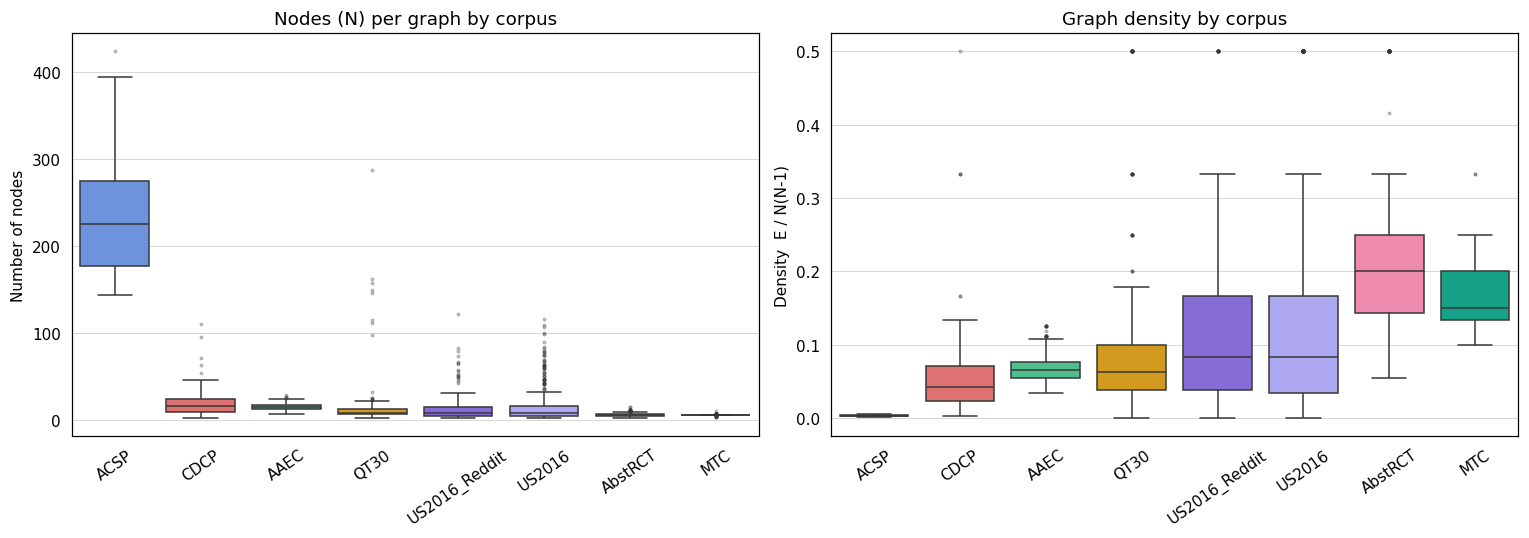

In [16]:
# ── Boxplots: N and density by corpus ────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

order = gdf.groupby('corpus')['N'].median().sort_values(ascending=False).index

sns.boxplot(data=gdf, x='corpus', y='N', order=order, ax=axes[0],
            palette=PALETTE, flierprops={'marker':'.','ms':3,'alpha':0.4})
axes[0].set_title('Nodes (N) per graph by corpus')
axes[0].set_xlabel(''); axes[0].tick_params(axis='x', rotation=35)
axes[0].set_ylabel('Number of nodes')

sns.boxplot(data=gdf, x='corpus', y='density', order=order, ax=axes[1],
            palette=PALETTE, flierprops={'marker':'.','ms':3,'alpha':0.4})
axes[1].set_title('Graph density by corpus')
axes[1].set_xlabel(''); axes[1].tick_params(axis='x', rotation=35)
axes[1].set_ylabel('Density  E / N(N-1)')

plt.tight_layout()
plt.savefig('fig_N_density_by_corpus.png', dpi=150, bbox_inches='tight')
plt.show()


In [18]:
# Leer el paper original de MTC (Peldszus & Stede 2015)
# o verificar con otro par más claro del mismo argumento

# S1 → S2: 
# S1: "it would be appropriate to only have those people pay..."  (claim)
# S2: "In some cases there are only shows for older generations..." (evidencia)
# ¿Quién apoya a quién? S2 justifica S1, pero la arista va S1→S2

# Si la arista va de claim a premisa, entonces:
# - out-degree alto = nodo que tiene muchas premisas que lo justifican = MajorClaim
# - in-degree alto  = premisa muy usada como soporte de múltiples claims

print("Roles bajo hipótesis: dirección claim → premisa")
for node in G_ex.nodes():
    ind  = G_ex.in_degree(node)
    outd = G_ex.out_degree(node)
    if outd > 0 and ind == 0:
        role = 'MajorClaim (emite, no recibe)'
    elif ind > 0 and outd > 0:
        role = 'Claim intermedia'
    elif ind > 0 and outd == 0:
        role = 'Premisa terminal'
    else:
        role = 'Aislada'
    print(f'  out={outd} in={ind} [{role}]')
    print(f'    {node[:70]}')

Roles bajo hipótesis: dirección claim → premisa
  out=3 in=0 [MajorClaim (emite, no recibe)]
    Considering what's on television these days, it would be appropriate t
  out=1 in=1 [Claim intermedia]
    so there's no advantage for the current paying viewers of the public b
  out=0 in=0 [Aislada]
    That shouldn't be an issue though, given the sheer number of programme
  out=0 in=1 [Premisa terminal]
    Nevertheless one has to point out that there'd probably be way fewer s
  out=0 in=1 [Premisa terminal]
    By now you have advertising on all channels,
  out=0 in=1 [Premisa terminal]
    In some cases there are only shows for older generations on at prime t


In [19]:
# ¿Cuántos nodos aislados hay por corpus?
isolated_by_corpus = (node_df[node_df['degree']==0]
                      .groupby('corpus').size()
                      .rename('n_isolated'))
total_by_corpus    = node_df.groupby('corpus').size().rename('n_total')

iso_df = pd.concat([isolated_by_corpus, total_by_corpus], axis=1).fillna(0)
iso_df['pct_isolated'] = (100 * iso_df['n_isolated'] / iso_df['n_total']).round(1)
iso_df = iso_df.sort_values('pct_isolated', ascending=False)

print(tabulate(iso_df.reset_index(), headers='keys', 
               tablefmt='rounded_outline', showindex=False))

╭───────────────┬──────────────┬───────────┬────────────────╮
│ corpus        │   n_isolated │   n_total │   pct_isolated │
├───────────────┼──────────────┼───────────┼────────────────┤
│ QT30          │         2146 │      7292 │           29.4 │
│ CDCP          │          421 │      1446 │           29.1 │
│ US2016_Reddit │          595 │      2182 │           27.3 │
│ US2016        │         1851 │      6821 │           27.1 │
│ MTC           │           77 │       576 │           13.4 │
│ AAEC          │          290 │      6028 │            4.8 │
│ ACSP          │            0 │      9357 │            0   │
│ AbstRCT       │            0 │      3472 │            0   │
╰───────────────┴──────────────┴───────────┴────────────────╯


---
## 5 · Constraint analysis

Constraints define which structural patterns are **allowed or forbidden**
by the annotation scheme. They matter for:
- GNN design (which edge types are valid)
- Post-processing rules (invalid predictions → correction)
- Understanding scheme differences across corpora

We analyse three types of constraints empirically from the data:

| Constraint type | Question |
|---|---|
| **Directionality** | Are relations always P1→P2 or do both directions appear? |
| **Relation co-occurrence** | Can two nodes have both Inference AND Conflict simultaneously? |
| **Structural constraints** | Can a root have in-edges? Can a cycle exist? |


In [17]:
# ── C1: Directionality — does (A→B) AND (B→A) appear in the same graph? ──
bidirectional_count = 0
total_checked = 0

for (corpus, arg), G in graphs.items():
    for u, v in G.edges():
        total_checked += 1
        if G.has_edge(v, u):
            bidirectional_count += 1

print('C1 — Bidirectional edges (A→B and B→A in same graph):')
print(f'  Found: {bidirectional_count} out of {total_checked} edges')
print(f'  → {"present" if bidirectional_count > 0 else "NOT present"} in the dataset')
print()

# ── C2: Multi-edge — can (A→B) have both Inference AND Conflict? ──────────
multi_edge_count = 0
for (corpus, arg), G in graphs.items():
    for u, v in G.edges():
        # In a DiGraph, only one edge per (u,v) pair — check for multi-rel
        # We need the raw pairs from df to detect this
        pass

# Check directly from df: same (arg, P1, P2) with different relations
multi_rel = (df[df['relations']!=0]
             .groupby([COL['argument'], COL['p1'], COL['p2']])[COL['relation']]
             .nunique())
n_multi = (multi_rel > 1).sum()
print('C2 — Multiple relations between same pair (A→B: both Inference and Conflict):')
print(f'  Found: {n_multi} pairs with > 1 relation type')
print(f'  → {"present" if n_multi > 0 else "NOT present — each pair has exactly 1 relation type"}')
print()

# ── C3: Self-loops ────────────────────────────────────────────────────────
# Already filtered (auto-arcs removed in Section 1)
print('C3 — Self-loops (P1 == P2):')
n_auto = (df_raw[COL['p1']] == df_raw[COL['p2']]).sum()
print(f'  Found in raw data: {n_auto} (all Neutral, removed in Section 1)')
print(f'  → Self-loops exist in the raw CSV but are always Neutral (no argumentative content)')


C1 — Bidirectional edges (A→B and B→A in same graph):
  Found: 6 out of 23441 edges
  → present in the dataset

C2 — Multiple relations between same pair (A→B: both Inference and Conflict):
  Found: 0 pairs with > 1 relation type
  → NOT present — each pair has exactly 1 relation type

C3 — Self-loops (P1 == P2):
  Found in raw data: 2759 (all Neutral, removed in Section 1)
  → Self-loops exist in the raw CSV but are always Neutral (no argumentative content)


In [81]:
# ── C4: In-degree of roots — should always be 0 ──────────────────────────
print('C4 — In-degree of root nodes:')
root_in_degrees = []
for (corpus, arg), G in graphs.items():
    for n in G.nodes():
        if G.in_degree(n) == 0 and G.out_degree(n) > 0:
            root_in_degrees.append(G.in_degree(n))

print(f'  All roots have in-degree = 0: {all(d==0 for d in root_in_degrees)}')
print('  (By definition — a root is a node with in-degree 0)')
print()

# ── C5: Relation type constraints per corpus ──────────────────────────────
print('C5 — Relation types present per corpus:')
rel_by_corpus = (df[df['relations']!=0]
                 .groupby(['corpus', COL['relation']]).size()
                 .unstack(fill_value=0))
rel_by_corpus.columns = [f'rel_{int(c)}' for c in rel_by_corpus.columns]
if 'rel_1' not in rel_by_corpus.columns: rel_by_corpus['rel_1'] = 0
if 'rel_2' not in rel_by_corpus.columns: rel_by_corpus['rel_2'] = 0
rel_by_corpus['has_inference'] = rel_by_corpus['rel_1'] > 0
rel_by_corpus['has_conflict']  = rel_by_corpus['rel_2'] > 0
rel_by_corpus['inf_conf_ratio'] = (rel_by_corpus['rel_1'] /
                                    rel_by_corpus['rel_2'].replace(0, np.nan)).round(2)
print(tabulate(rel_by_corpus.reset_index(), headers='keys',
               tablefmt='rounded_outline', showindex=False))


C4 — In-degree of root nodes:
  All roots have in-degree = 0: True
  (By definition — a root is a node with in-degree 0)

C5 — Relation types present per corpus:
╭───────────────┬─────────┬─────────┬─────────────────┬────────────────┬──────────────────╮
│ corpus        │   rel_1 │   rel_2 │ has_inference   │ has_conflict   │   inf_conf_ratio │
├───────────────┼─────────┼─────────┼─────────────────┼────────────────┼──────────────────┤
│ AAEC          │    4841 │     497 │ True            │ True           │             9.74 │
│ ACSP          │    8069 │     697 │ True            │ True           │            11.58 │
│ AbstRCT       │    2290 │     344 │ True            │ True           │             6.66 │
│ CDCP          │     692 │      82 │ True            │ True           │             8.44 │
│ MTC           │     272 │     108 │ True            │ True           │             2.52 │
│ QT30          │    2712 │     545 │ True            │ True           │             4.98 │
│ US2016  

In [82]:
# ── C6: Summary constraint table ─────────────────────────────────────────
print('=== CONSTRAINT SUMMARY ===')
print()
constraints = [
    ('C1', 'Bidirectional edges (A→B and B→A)',
     'absent' if bidirectional_count==0 else f'present ({bidirectional_count} cases)',
     'Edges are directed and non-symmetric'),
    ('C2', 'Multi-relation same pair (Inf + Conf)',
     'absent' if n_multi==0 else f'present ({n_multi} cases)',
     'Each ordered pair has exactly one relation type'),
    ('C3', 'Self-loops (P1=P2)',
     'present in raw data (always Neutral)',
     'Filtered before graph construction'),
    ('C4', 'Root in-degree > 0',
     'impossible by definition',
     'Roots are defined as in-degree=0'),
    ('C5', 'Conflict-only corpus',
     'none — all corpora have Inference',
     'MTC and AAEC are the most balanced'),
    ('C6', 'Cycles',
     f'{n_cyclic} graphs ({100*n_cyclic/len(gdf):.1f}%)',
     'Present but rare — may indicate annotation noise'),
]

c_df = pd.DataFrame(constraints, columns=['ID','Constraint','Status','Implication'])
print(tabulate(c_df, headers='keys', tablefmt='rounded_outline', showindex=False))


=== CONSTRAINT SUMMARY ===

╭──────┬───────────────────────────────────────┬──────────────────────────────────────┬──────────────────────────────────────────────────╮
│ ID   │ Constraint                            │ Status                               │ Implication                                      │
├──────┼───────────────────────────────────────┼──────────────────────────────────────┼──────────────────────────────────────────────────┤
│ C1   │ Bidirectional edges (A→B and B→A)     │ present (6 cases)                    │ Edges are directed and non-symmetric             │
│ C2   │ Multi-relation same pair (Inf + Conf) │ absent                               │ Each ordered pair has exactly one relation type  │
│ C3   │ Self-loops (P1=P2)                    │ present in raw data (always Neutral) │ Filtered before graph construction               │
│ C4   │ Root in-degree > 0                    │ impossible by definition             │ Roots are defined as in-degree=0                 │

In [1]:
# Leer el paper original de MTC (Peldszus & Stede 2015)
# o verificar con otro par más claro del mismo argumento

# S1 → S2: 
# S1: "it would be appropriate to only have those people pay..."  (claim)
# S2: "In some cases there are only shows for older generations..." (evidencia)
# ¿Quién apoya a quién? S2 justifica S1, pero la arista va S1→S2

# Si la arista va de claim a premisa, entonces:
# - out-degree alto = nodo que tiene muchas premisas que lo justifican = MajorClaim
# - in-degree alto  = premisa muy usada como soporte de múltiples claims

print("Roles bajo hipótesis: dirección claim → premisa")
for node in G_ex.nodes():
    ind  = G_ex.in_degree(node)
    outd = G_ex.out_degree(node)
    if outd > 0 and ind == 0:
        role = 'MajorClaim (emite, no recibe)'
    elif ind > 0 and outd > 0:
        role = 'Claim intermedia'
    elif ind > 0 and outd == 0:
        role = 'Premisa terminal'
    else:
        role = 'Aislada'
    print(f'  out={outd} in={ind} [{role}]')
    print(f'    {node[:70]}')

Roles bajo hipótesis: dirección claim → premisa


NameError: name 'G_ex' is not defined

---
## Next step — Notebook 03: Component Analysis

| Level | Notebook | Content |
|---|---|---|
| **3** | `03_component_analysis.ipynb` | ADU types, span length, coverage, intra/inter-sentence distance |
| **4** | `04_relation_analysis.ipynb` | Relation direction, distance P1→P2, forward vs backward arcs |
| **5** | `05_modelling_features.ipynb` | Class imbalance per subtask, baselines, cross-dataset compatibility |

**Variables available for Notebook 03:**
```python
df        # clean DataFrame (auto-arcs removed)
gdf       # graph-level metrics (one row per document)
node_df   # node-level metrics (one row per ADU per document)
graphs    # dict {(corpus, argument) → nx.DiGraph}
COL       # column mapping
```
